In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style('darkgrid')


In [2]:
df = sns.load_dataset('tips')

In [3]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


# **Measure of Central Tendency**

19.79
17.80
13.42


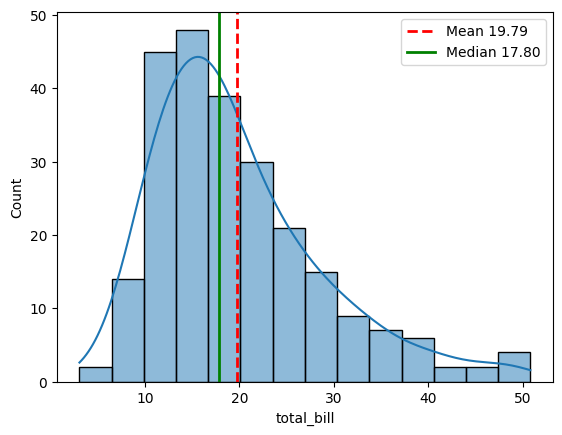

In [25]:
col = df['total_bill']
total_bill_mean = np.mean(col)
total_bill_median = np.median(col)
total_bill_mode = df['total_bill'].mode()
print(f"{total_bill_mean:.2f}")
print(f"{total_bill_median:.2f}")
print(f"{total_bill_mode[0]:.2f}")
sns.histplot(col,kde=True)

plt.axvline(total_bill_mean,color='red',linestyle='dashed',linewidth=2,label=f"Mean {total_bill_mean:.2f}")
plt.axvline(total_bill_median,color='green',linestyle='solid',linewidth=2,label=f"Median {total_bill_median:.2f}")
plt.legend()
plt.show()


# **Measure of Spread**

In [30]:
data_range = np.max(col) -  np.min(col)
variance = np.var(col)
std_dev = np.std(col)

#inter quertile range
q1 = np.percentile(col,25)
q2 = np.percentile(col,50)
q3 = np.percentile(col,75)
iqr = q3 -q1

print(f"Range {data_range:.2f}")
print(f"Variance {variance:.2f}")
print(f"Standard Deviation {std_dev:.2f}")
print(f"Q1: {q1} , Q3: {q3} ,Inter Quartile Range {iqr:.2f}")

Range 47.74
Variance 78.93
Standard Deviation 8.88
Q1: 13.3475 , Q3: 24.127499999999998 ,Inter Quartile Range 10.78


<Axes: ylabel='total_bill'>

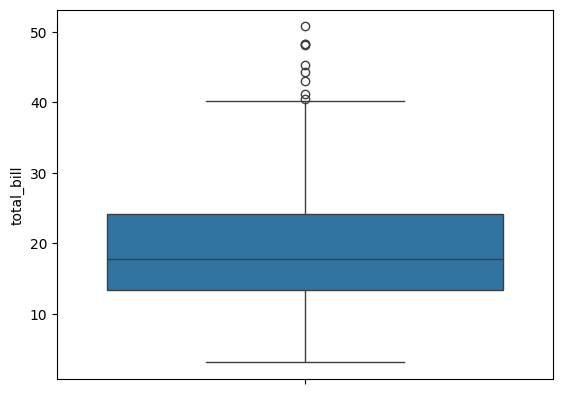

In [33]:
sns.boxplot(data=col)

In [34]:
df.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


3.00
2.90
13.42


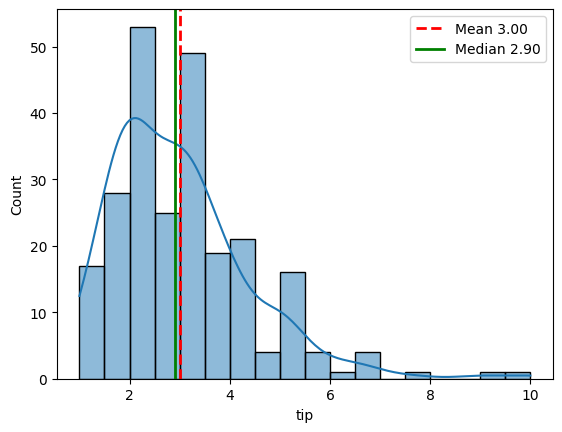

In [35]:
col = df['tip']
total_bill_mean = np.mean(col)
total_bill_median = np.median(col)
total_bill_mode = df['total_bill'].mode()
print(f"{total_bill_mean:.2f}")
print(f"{total_bill_median:.2f}")
print(f"{total_bill_mode[0]:.2f}")
sns.histplot(col,kde=True)

plt.axvline(total_bill_mean,color='red',linestyle='dashed',linewidth=2,label=f"Mean {total_bill_mean:.2f}")
plt.axvline(total_bill_median,color='green',linestyle='solid',linewidth=2,label=f"Median {total_bill_median:.2f}")
plt.legend()
plt.show()


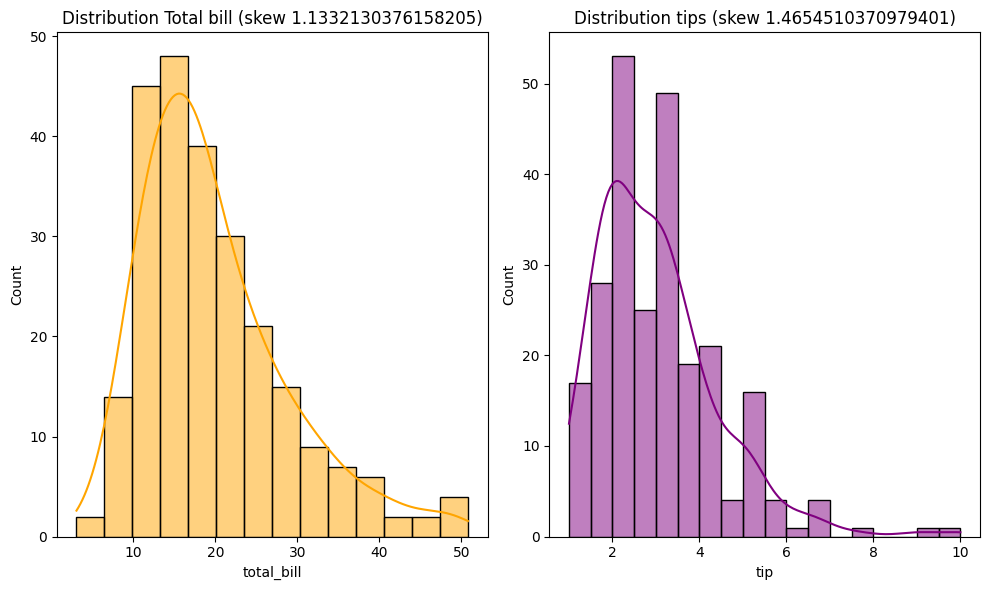

In [45]:
col = df['total_bill']
plt.figure(figsize=(10,6))
skew = col.skew()
plt.subplot(1,2,1)
sns.histplot(col,kde=True,color='orange')
plt.title(f"Distribution Total bill (skew {skew})")
col = df['tip']
skew = col.skew()
plt.subplot(1,2,2)
sns.histplot(col,kde=True,color='purple')
plt.title(f"Distribution tips (skew {skew})")
plt.tight_layout()
plt.show()

Outlier Detection

In [46]:
q1 = df['total_bill'].quantile(.25)
q3 = df['total_bill'].quantile(.75)
iqr = q3 - q1
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)
print(f"Lower Bound {lower_bound:.2f}")
print(f"Upper Bound {upper_bound:.2f}")


Lower Bound -2.82
Upper Bound 40.30


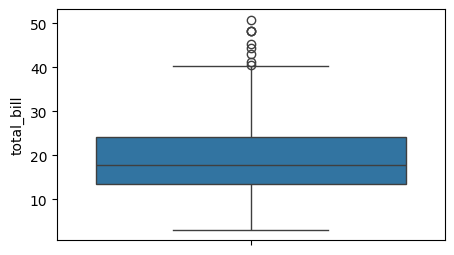

In [48]:
plt.figure(figsize=(5,3))
sns.boxplot(df['total_bill'])
plt.show()

In [51]:
outlier = df[(df['total_bill'] < lower_bound) | (df['total_bill'] > upper_bound)]
print(outlier['total_bill'])

59     48.27
102    44.30
142    41.19
156    48.17
170    50.81
182    45.35
184    40.55
197    43.11
212    48.33
Name: total_bill, dtype: float64


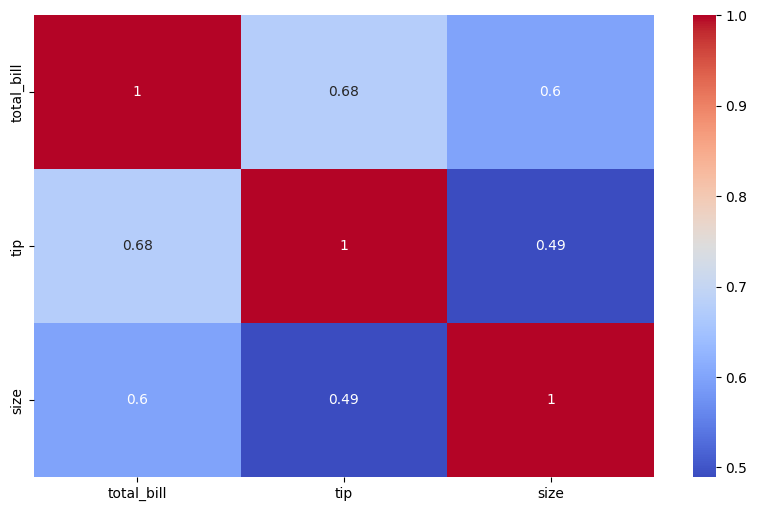

In [54]:
df = df.select_dtypes(include='number')
df_corr = df.corr()
plt.figure(figsize=(10,6))
sns.heatmap(df_corr,annot=True,cmap='coolwarm')
plt.show()

In [56]:
print(df_corr)
print(df_corr.loc['total_bill','tip'])

            total_bill       tip      size
total_bill    1.000000  0.675734  0.598315
tip           0.675734  1.000000  0.489299
size          0.598315  0.489299  1.000000
0.6757341092113648
